In [1]:
import pandas as pd 
import numpy as np


In [ ]:
data_folder = "C:/Drive/Projects/Aeron/data/"
csv_folder = "C:/Drive/Projects/Aeron/data/csvfiles/"
gps_folder = "C:/Drive/Projects/Aeron/data/gps/"
stations_data = "C:/Drive/Projects/Aeron/data/stations.csv"


In [ ]:
stations_df = pd.read_csv(stations_data)
stations_df.sort_values(by='installed', inplace=True)
stations_df.head(10)

C:\Users\neilc\AppData\Local\Temp\ipykernel_34760\499185629.py:2: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  stations_df.sort_values(by='installed', inplace=True)


,station_id,name,lat,lon,elevation_m,installed,logger_interval_min
1,S02,North Mesa School,40.0352,-105.2308,1623,2022-09-01,10
2,S03,Valley Library,40.1757,-105.1472,1523,2022-09-01,10
6,S07,Riverbend Farm,40.5975,-105.0212,1525,2022-11-12,10
3,S04,Foothills Community Garden,39.7540,-105.1460,1763,2023-04-15,10
0,S01,Saddle Ridge Hut,39.8946,-105.5649,2913,2023-06-10,10
5,S06,South Hills Fire Station,39.4025,-104.9171,1891,2023-08-05,10
4,S05,Eastside Rec Centre,39.5700,-104.8957,1644,2024-02-20,10
7,S08,Plains Grange Hall,40.3866,-104.7042,1437,2024-05-30,10


# How old each station is

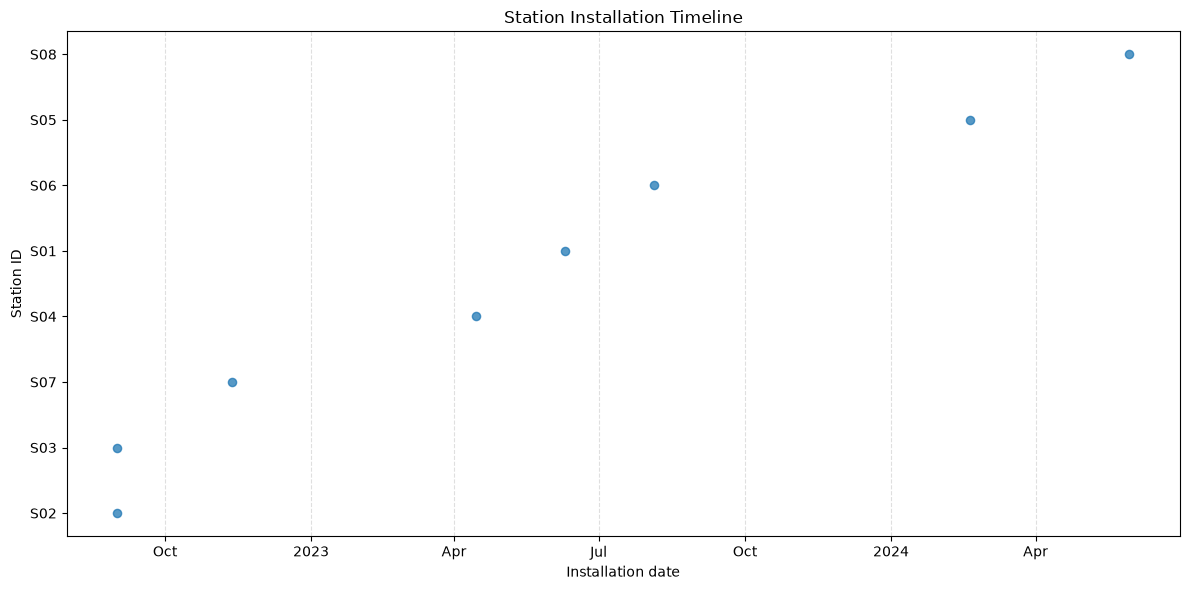

In [14]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

plot_df = stations_df[['installed', 'station_id']].copy()
plot_df['installed'] = pd.to_datetime(plot_df['installed'], errors='coerce')
plot_df = plot_df.dropna(subset=['installed', 'station_id']).sort_values('installed')

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(plot_df['installed'], plot_df['station_id'], alpha=0.75, s=35)

ax.set(
    xlabel='Installation date',
    ylabel='Station ID',
    title='Station Installation Timeline',
)
locator = mdates.AutoDateLocator()
ax.xaxis.set_major_locator(locator)
ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
ax.grid(axis='x', linestyle='--', alpha=0.4)

fig.tight_layout()
plt.show()

In [15]:
s01 = pd.read_csv(csv_folder + "S01.csv", parse_dates=["timestamp_utc"])
s01.describe()

,temp_c,rh_pct,pressure_hpa,wind_kmh,wind_dir_deg,rain_mm,ghi_wm2
count,6048.000000,6048.000000,6048.000000,6048.000000,6048.000000,6048.000000,6048.000000
mean,5.825132,50.391204,835.150595,8.869924,192.371858,0.011607,210.387897
std,7.191870,24.704486,9.340852,6.210217,96.914682,0.062927,276.383681
min,-11.700000,4.000000,806.800000,0.000000,0.000000,0.000000,0.000000
25%,0.400000,29.000000,829.100000,4.300000,101.000000,0.000000,0.000000
50%,4.100000,50.000000,835.200000,7.400000,234.000000,0.000000,20.000000
75%,10.600000,70.000000,841.300000,11.900000,259.000000,0.000000,420.000000
max,27.600000,100.000000,857.600000,49.500000,360.000000,0.600000,989.000000


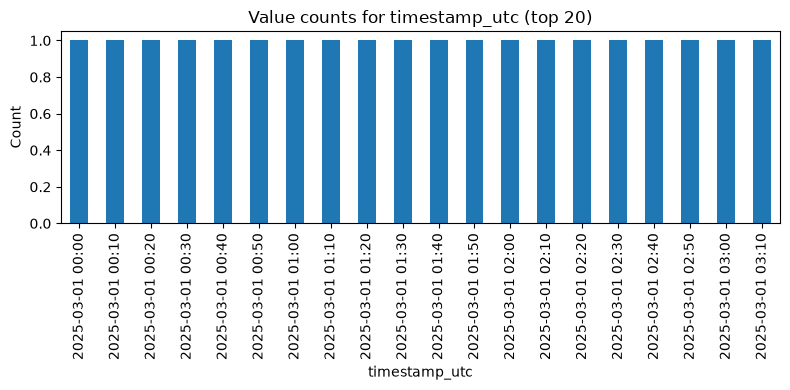

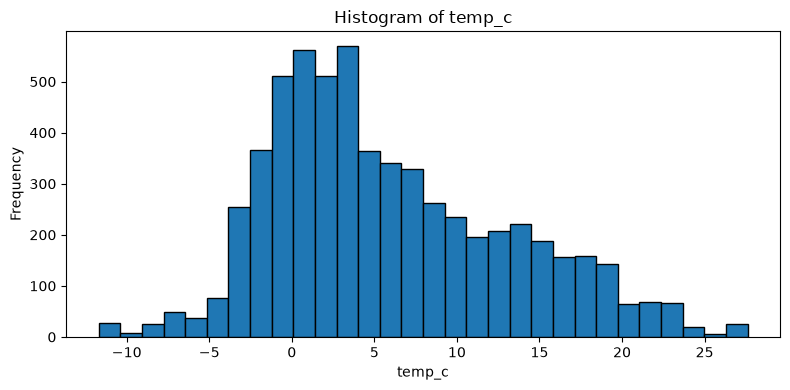

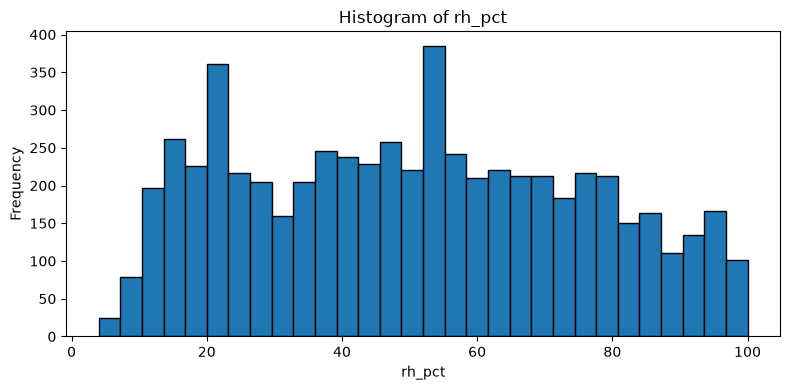

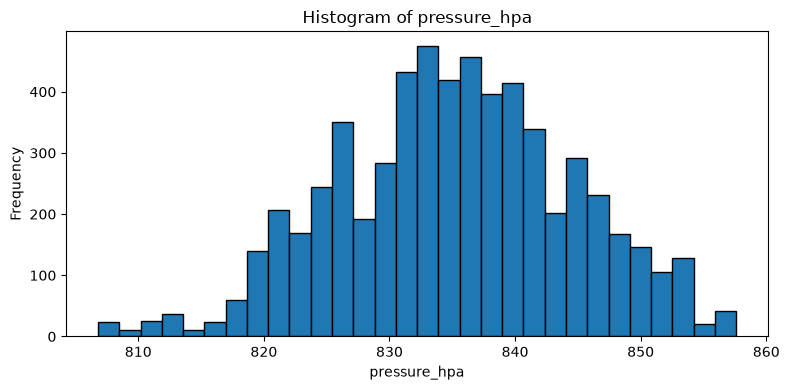

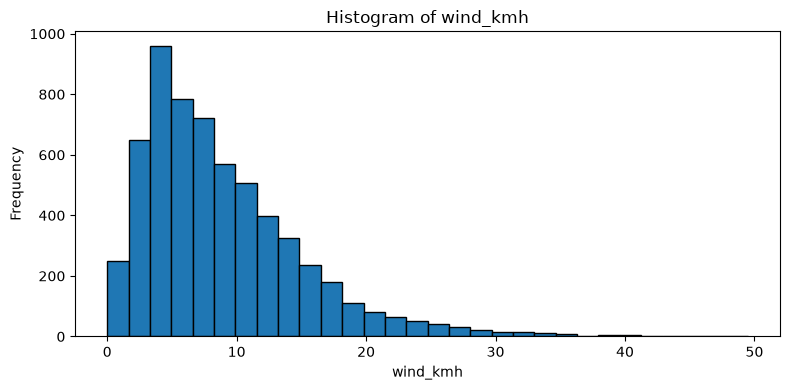

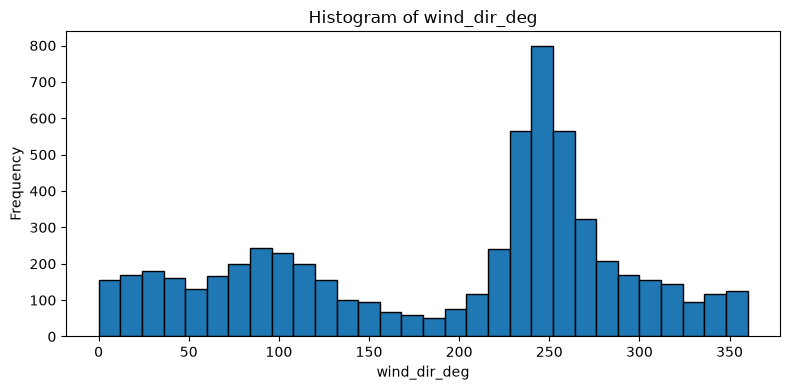

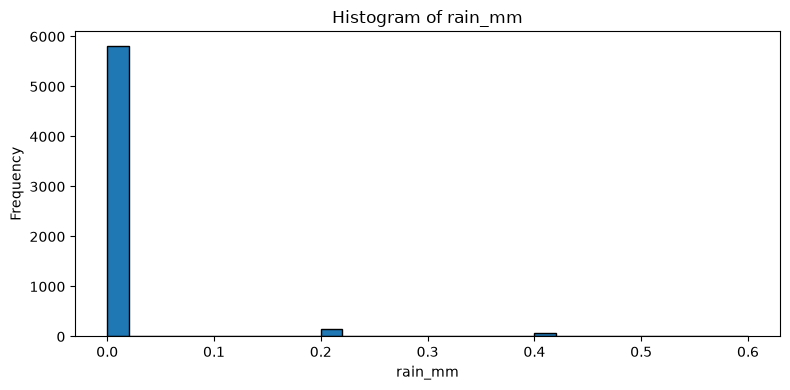

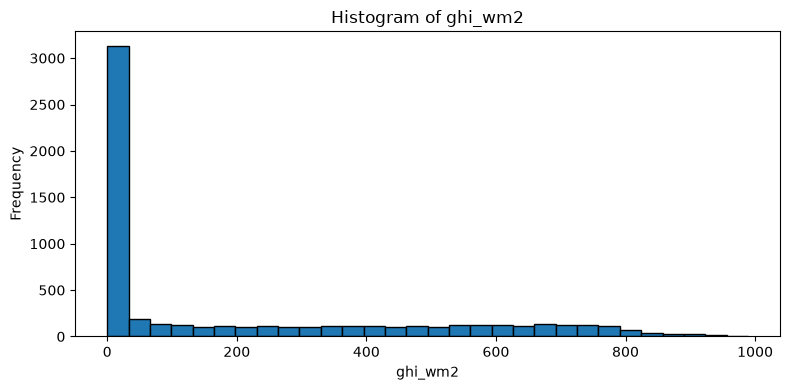

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

for col in s01.columns:
    data = s01[col].dropna()

    if data.empty:
        continue

    plt.figure(figsize=(8, 4))

    if pd.api.types.is_numeric_dtype(data):
        plt.hist(data, bins=30, edgecolor="black")
        plt.ylabel("Frequency")
        plt.title(f"Histogram of {col}")
    else:
        # Histograms need numeric data; show category frequencies for other columns.
        data.astype(str).value_counts().head(20).plot(kind="bar")
        plt.ylabel("Count")
        plt.title(f"Value counts for {col} (top 20)")

    plt.xlabel(col)
    plt.tight_layout()
    plt.show()

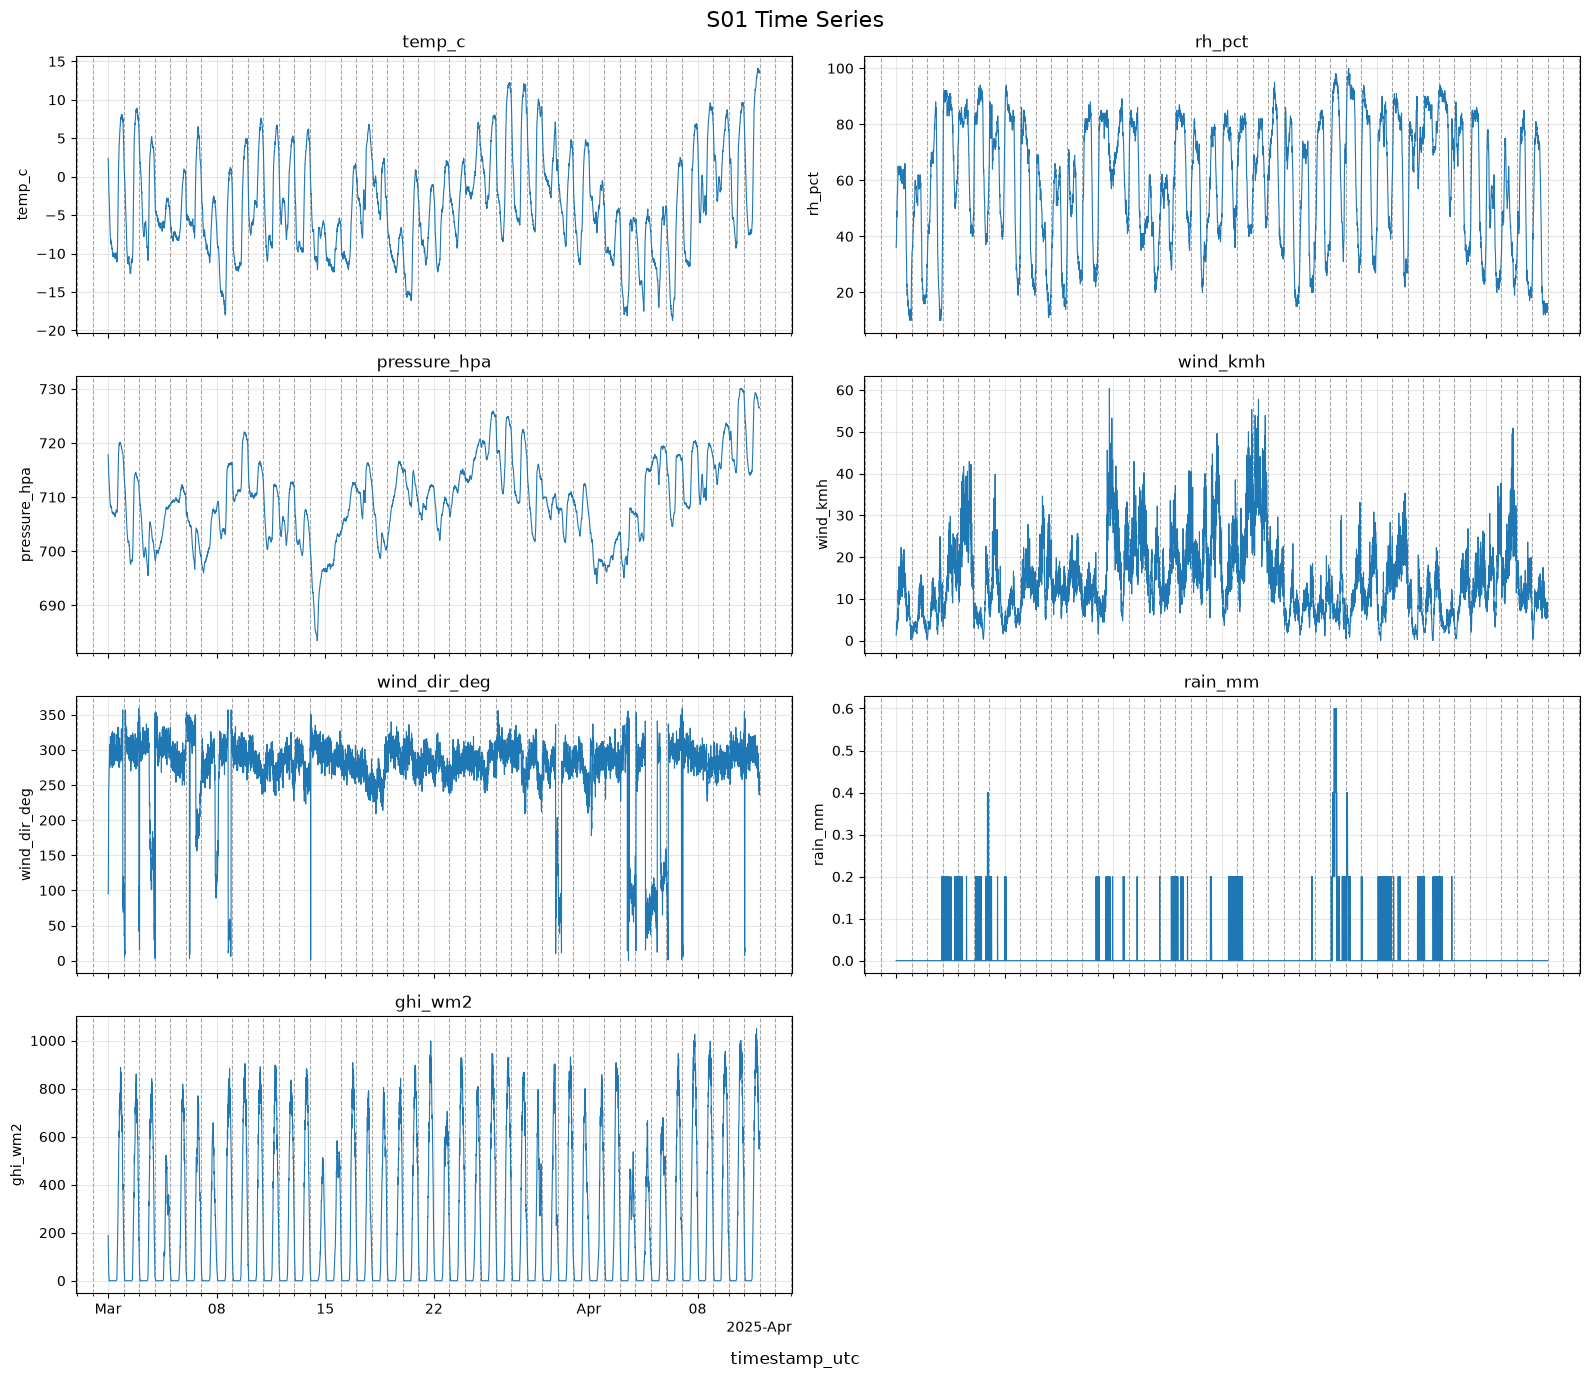

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Load S01 data and parse its timestamp column
s01 = pd.read_csv(
    csv_folder + "S01.csv",
    parse_dates=["timestamp_utc"]
)

time_col = "timestamp_utc"
df = s01.dropna(subset=[time_col]).sort_values(time_col)

# Plot each numeric measurement in its own subplot
value_cols = df.select_dtypes(include="number").columns.tolist()
fig, axes = plt.subplots(4, 2, figsize=(16, 14), sharex=True)

for ax, col in zip(axes.flat, value_cols):
    ax.plot(df[time_col], df[col], linewidth=0.8)
    ax.set_title(col)
    ax.set_ylabel(col)
    ax.grid(True, alpha=0.3)

# Remove any unused subplot
for ax in axes.flat[len(value_cols):]:
    ax.remove()

locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)

for ax in fig.axes:
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(formatter)

    # Add a vertical gridline at midnight each day
    ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=0))
    ax.grid(
        which="minor",
        axis="x",
        linestyle="--",
        linewidth=0.8,
        color="gray",
        alpha=0.7,
    )

fig.supxlabel(time_col)
fig.suptitle("S01 Time Series", fontsize=16)
fig.tight_layout()
plt.show()

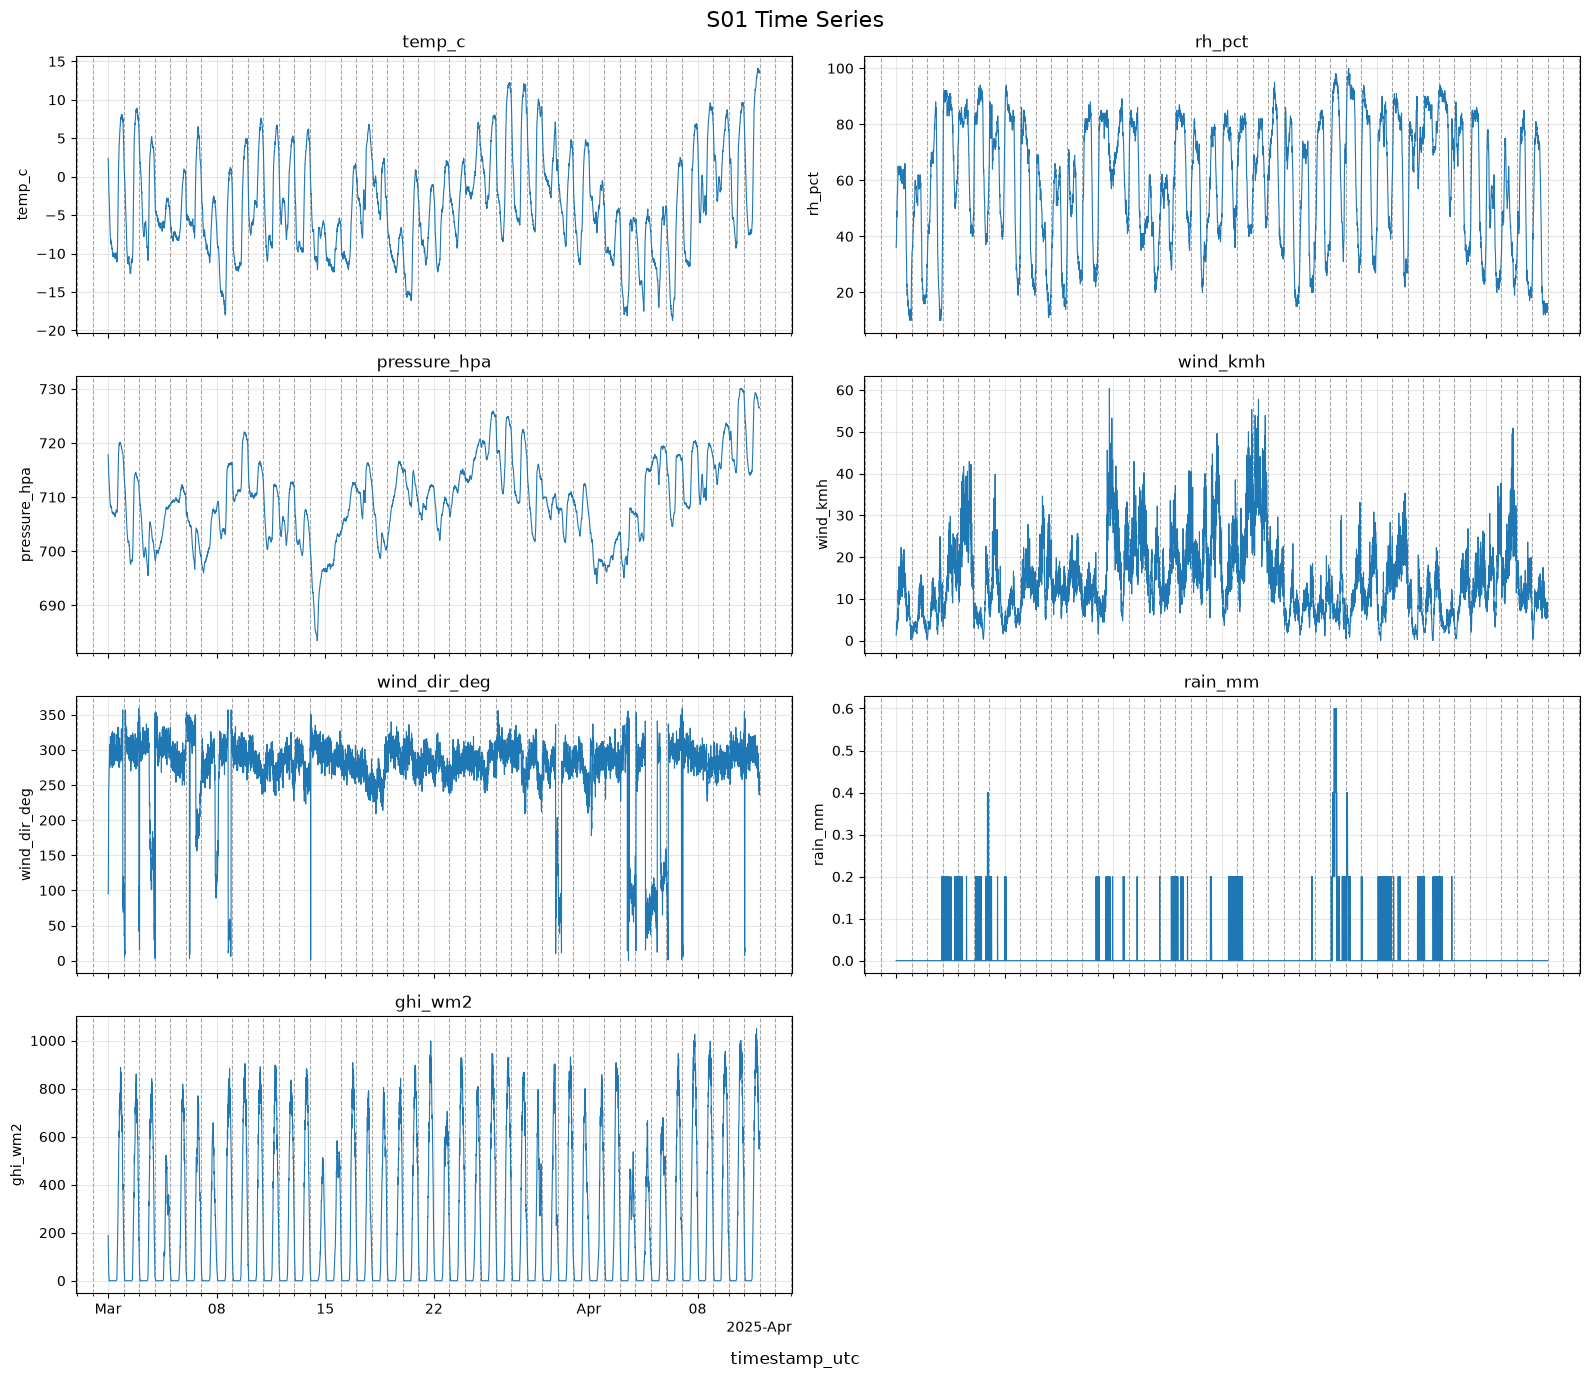

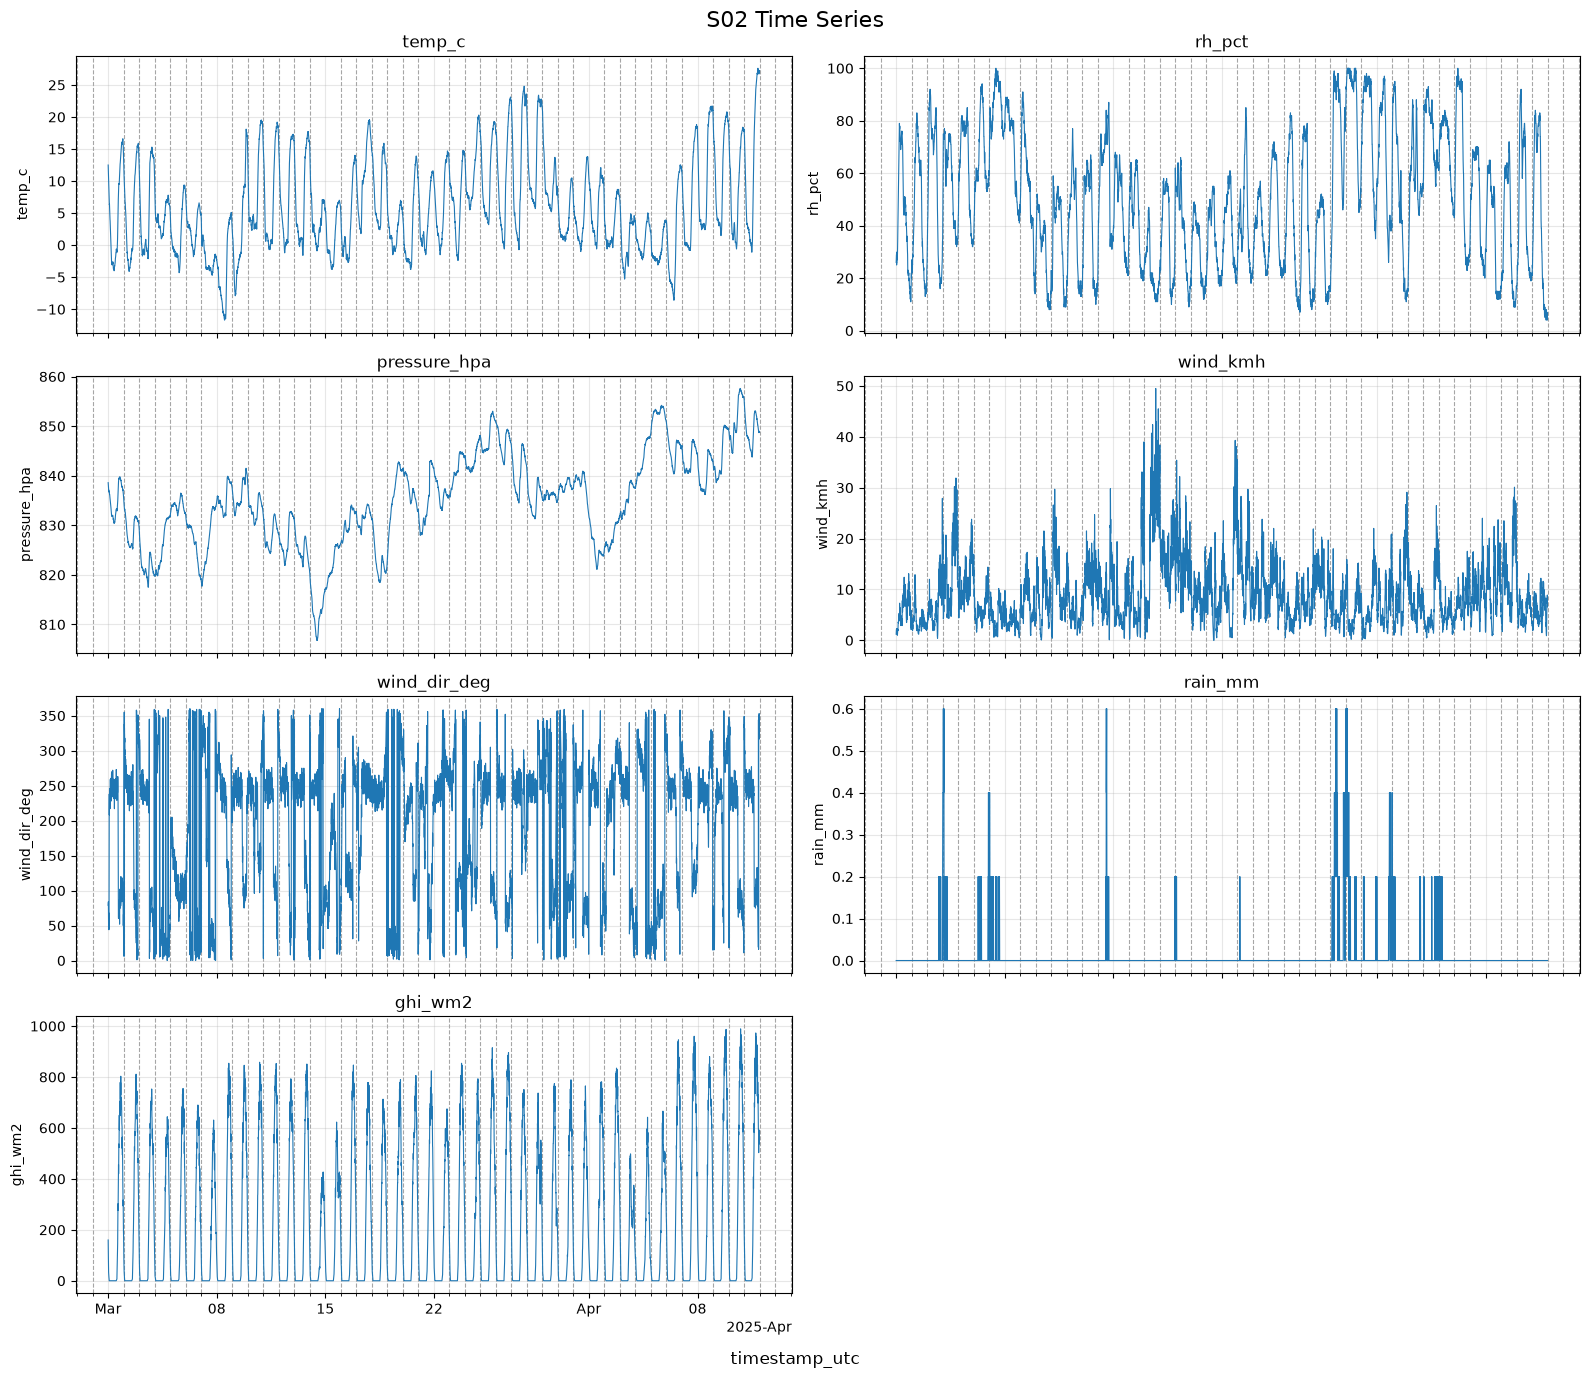

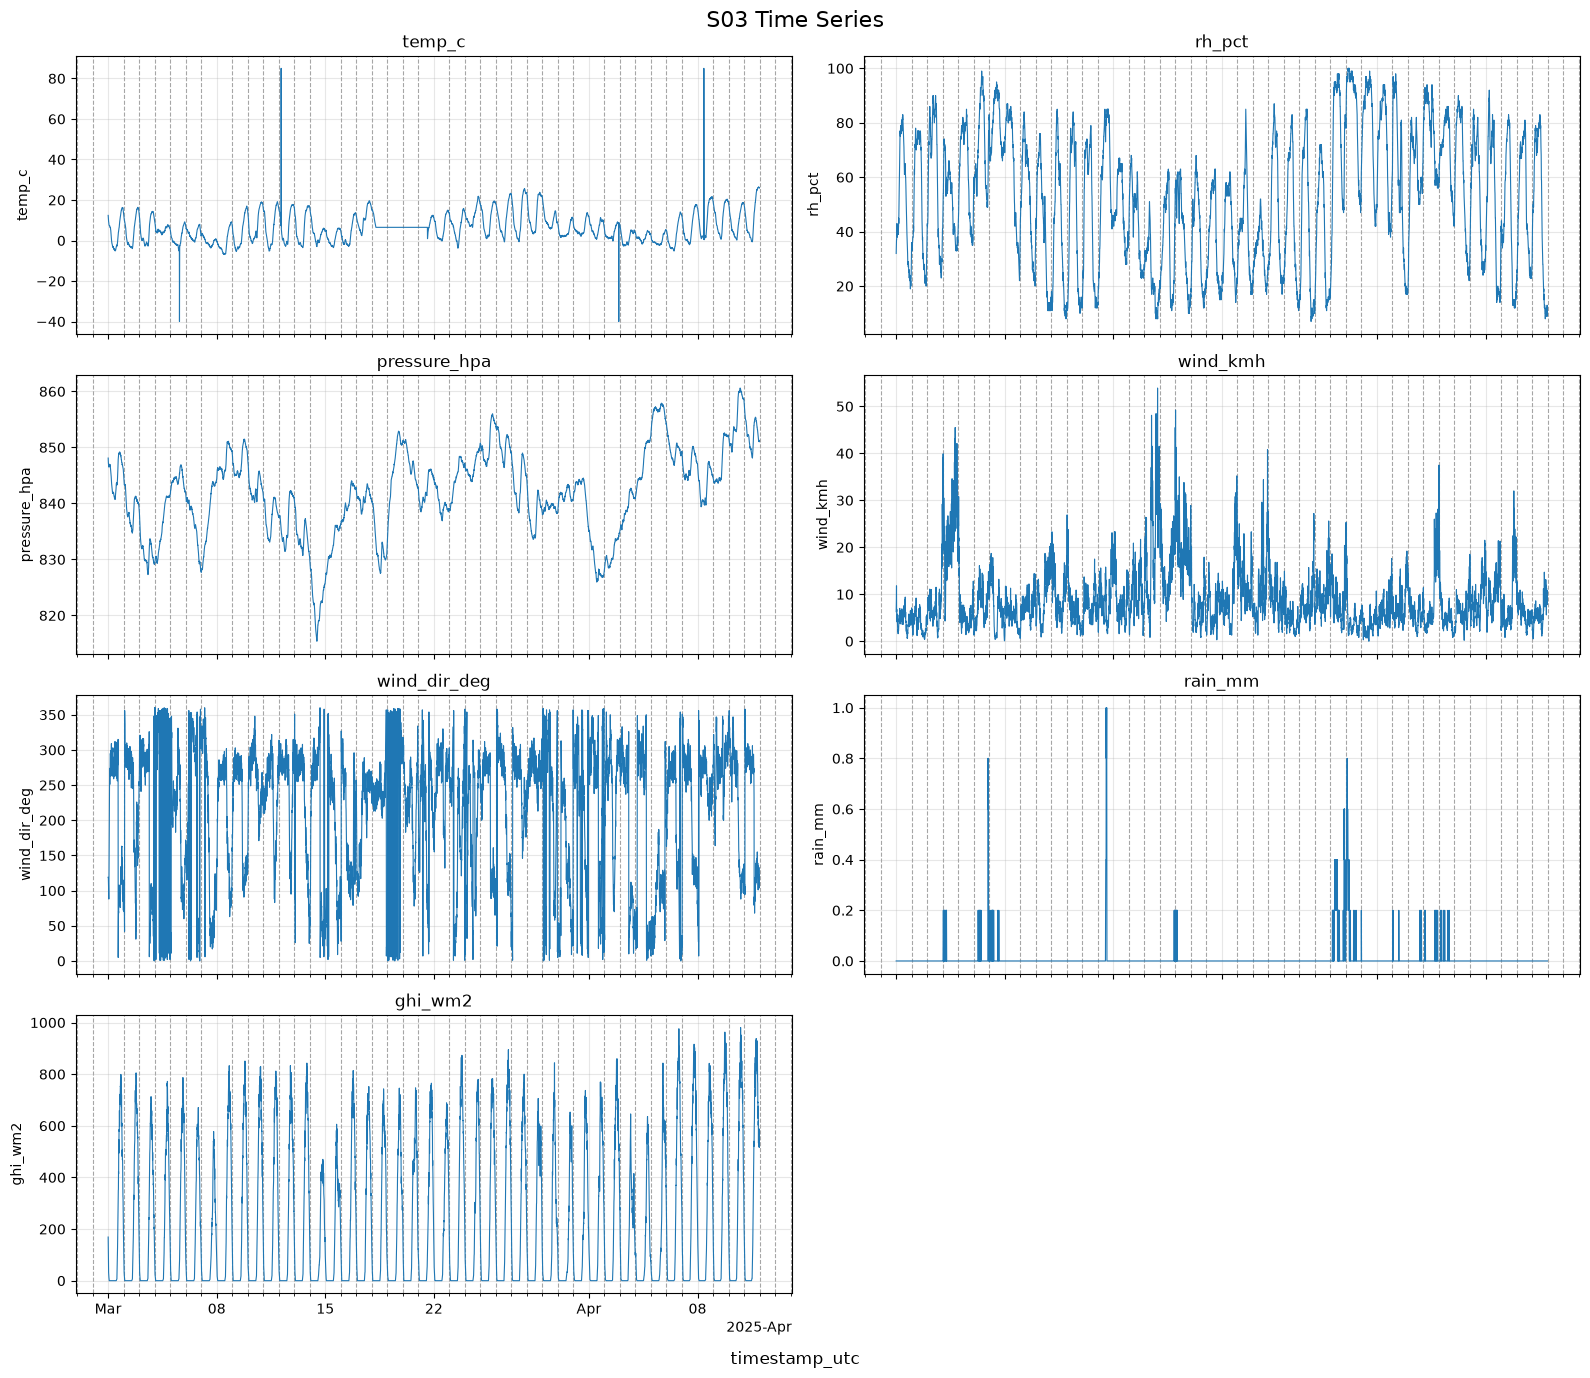

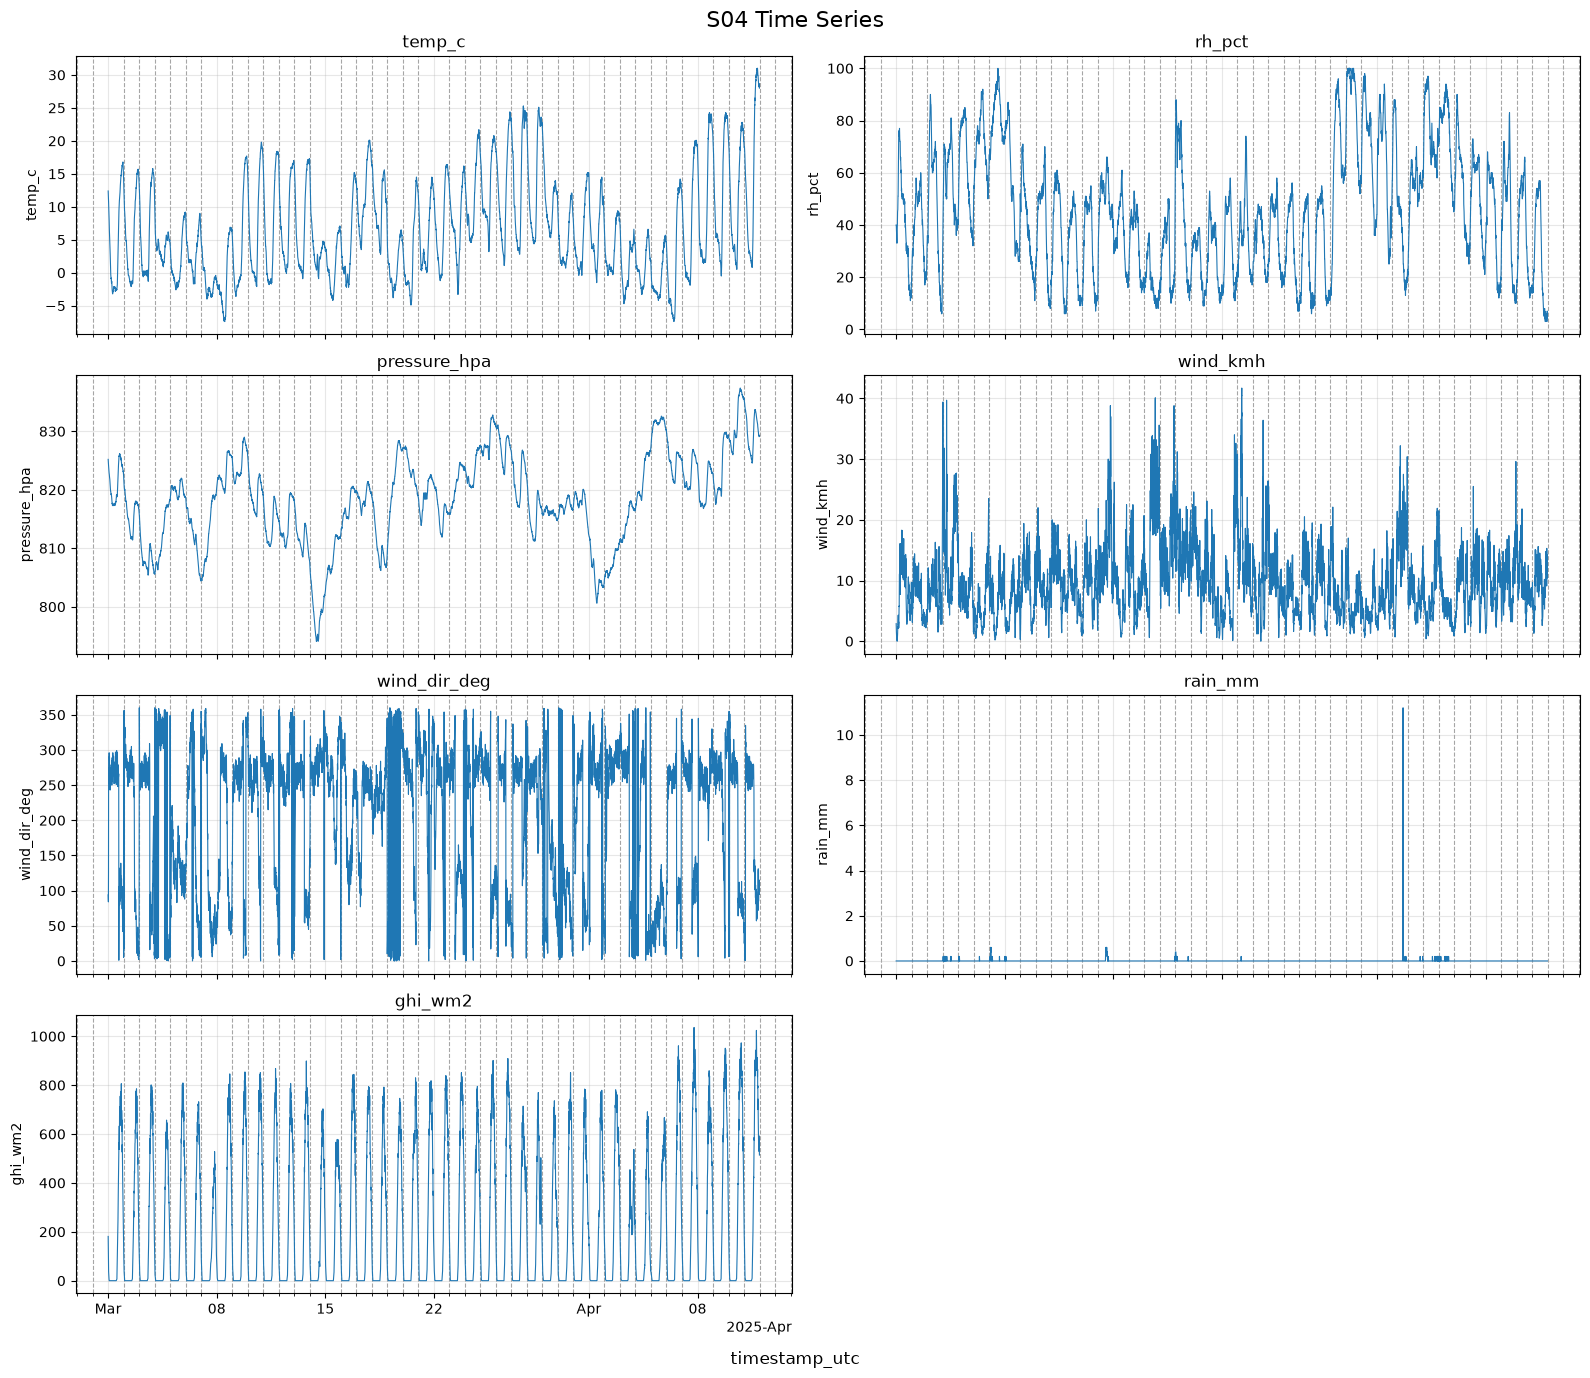

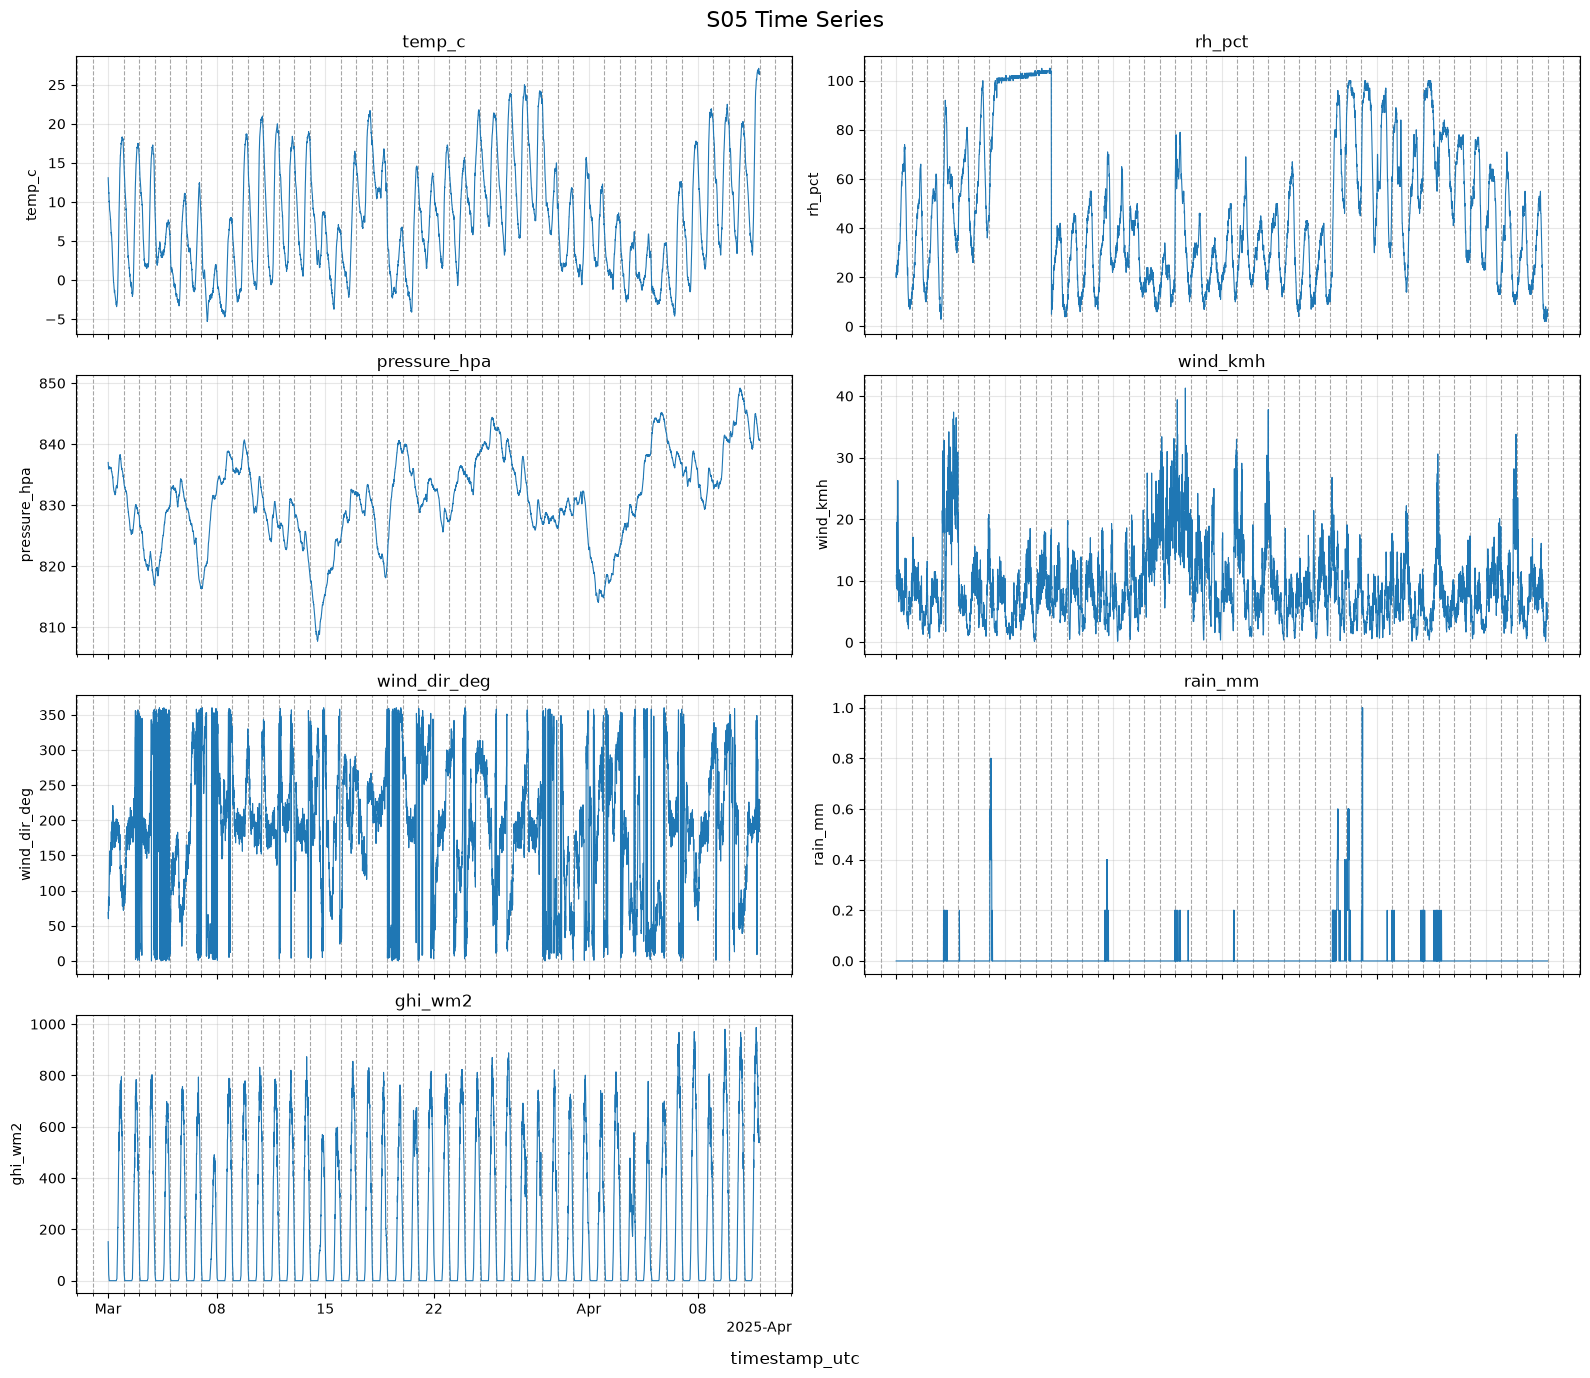

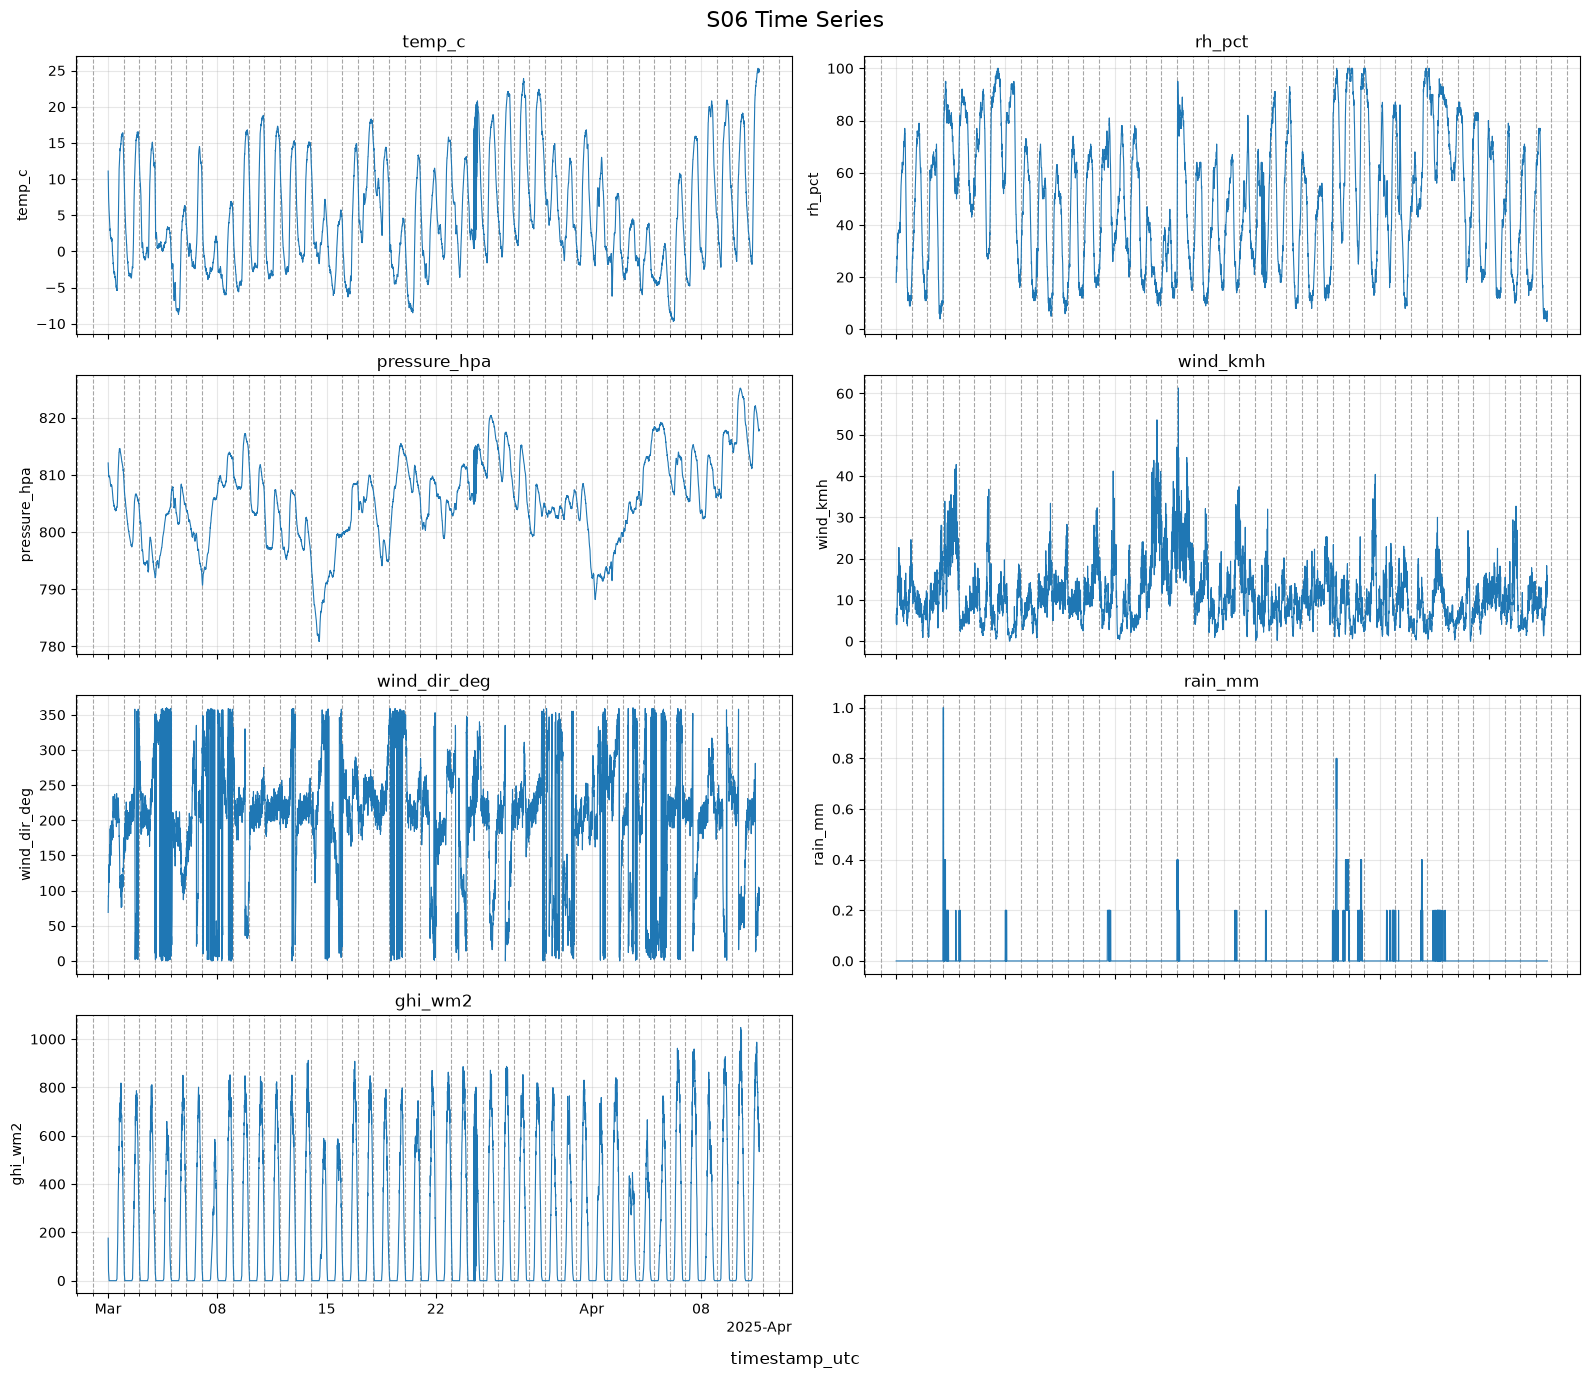

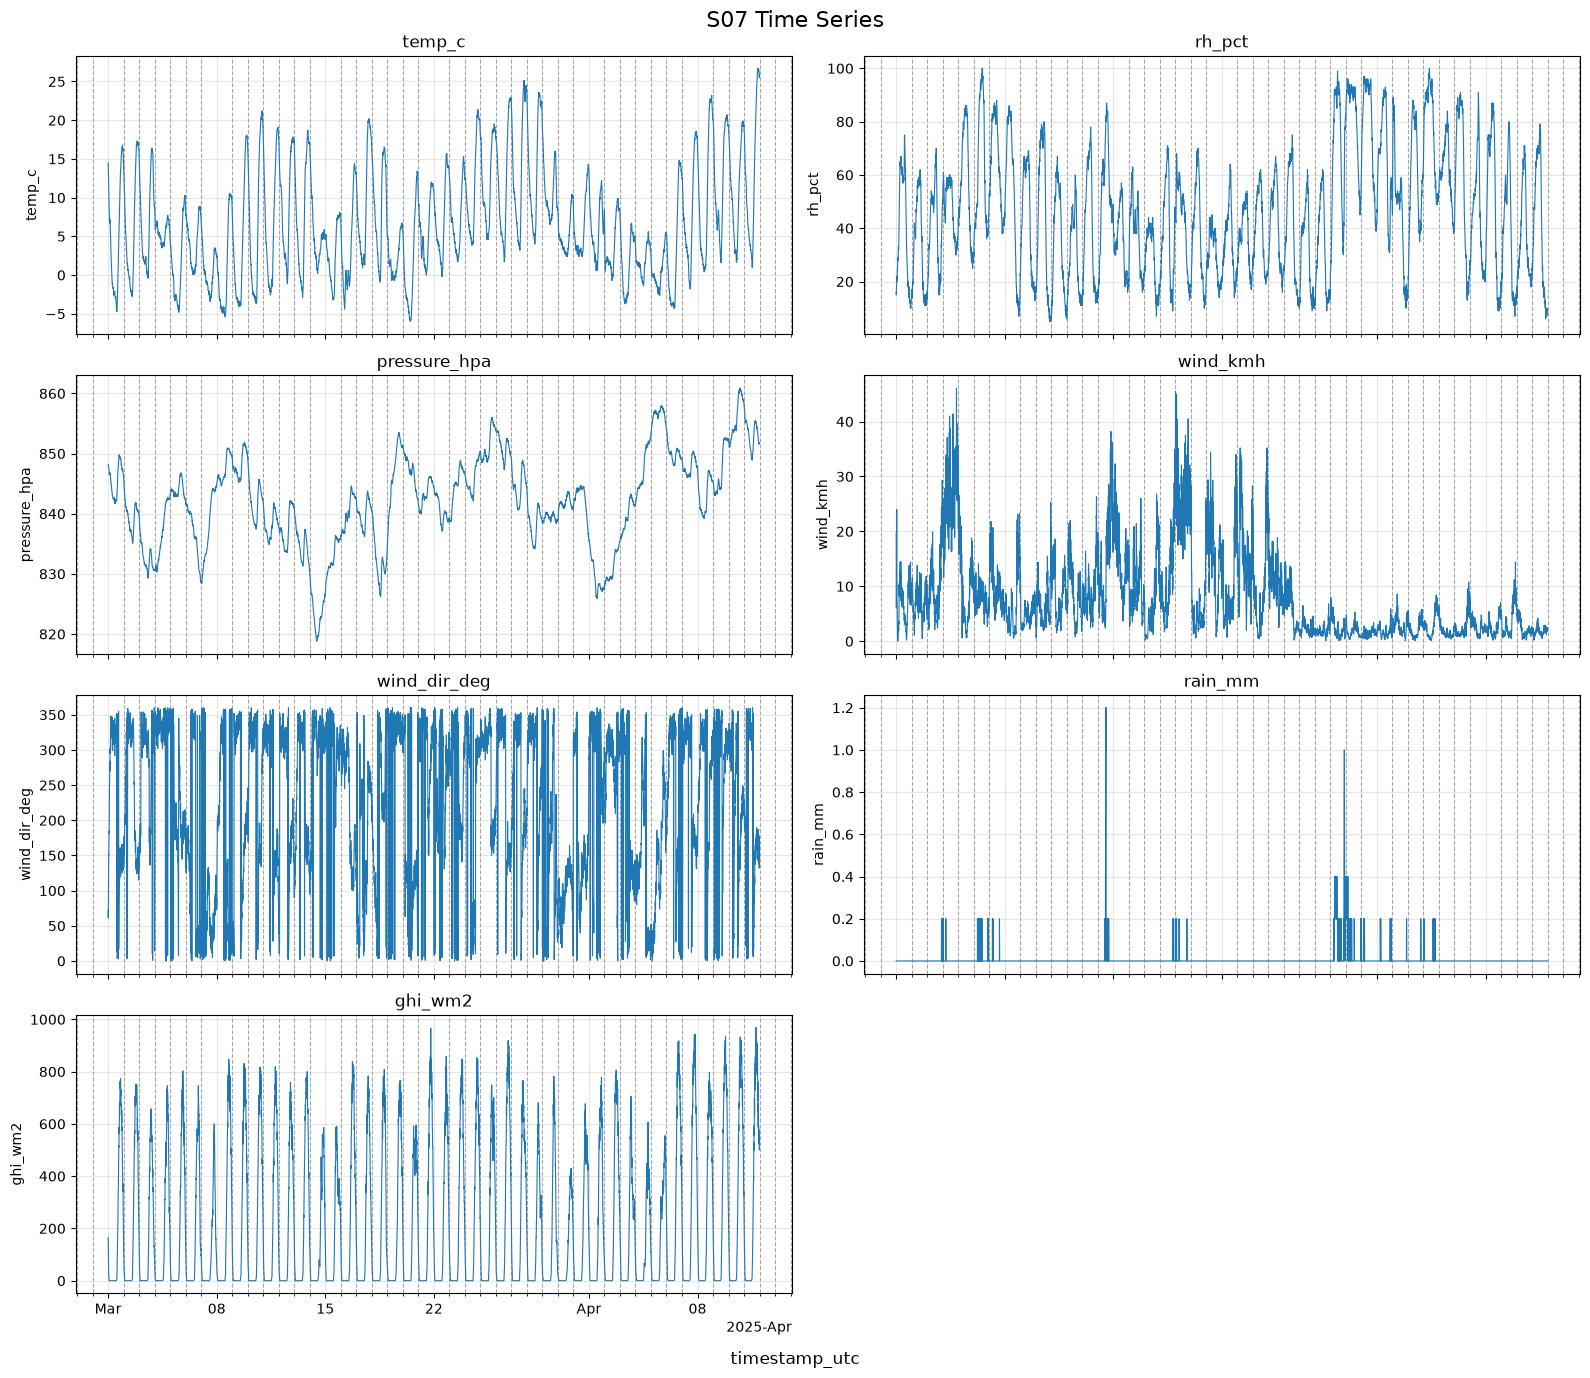

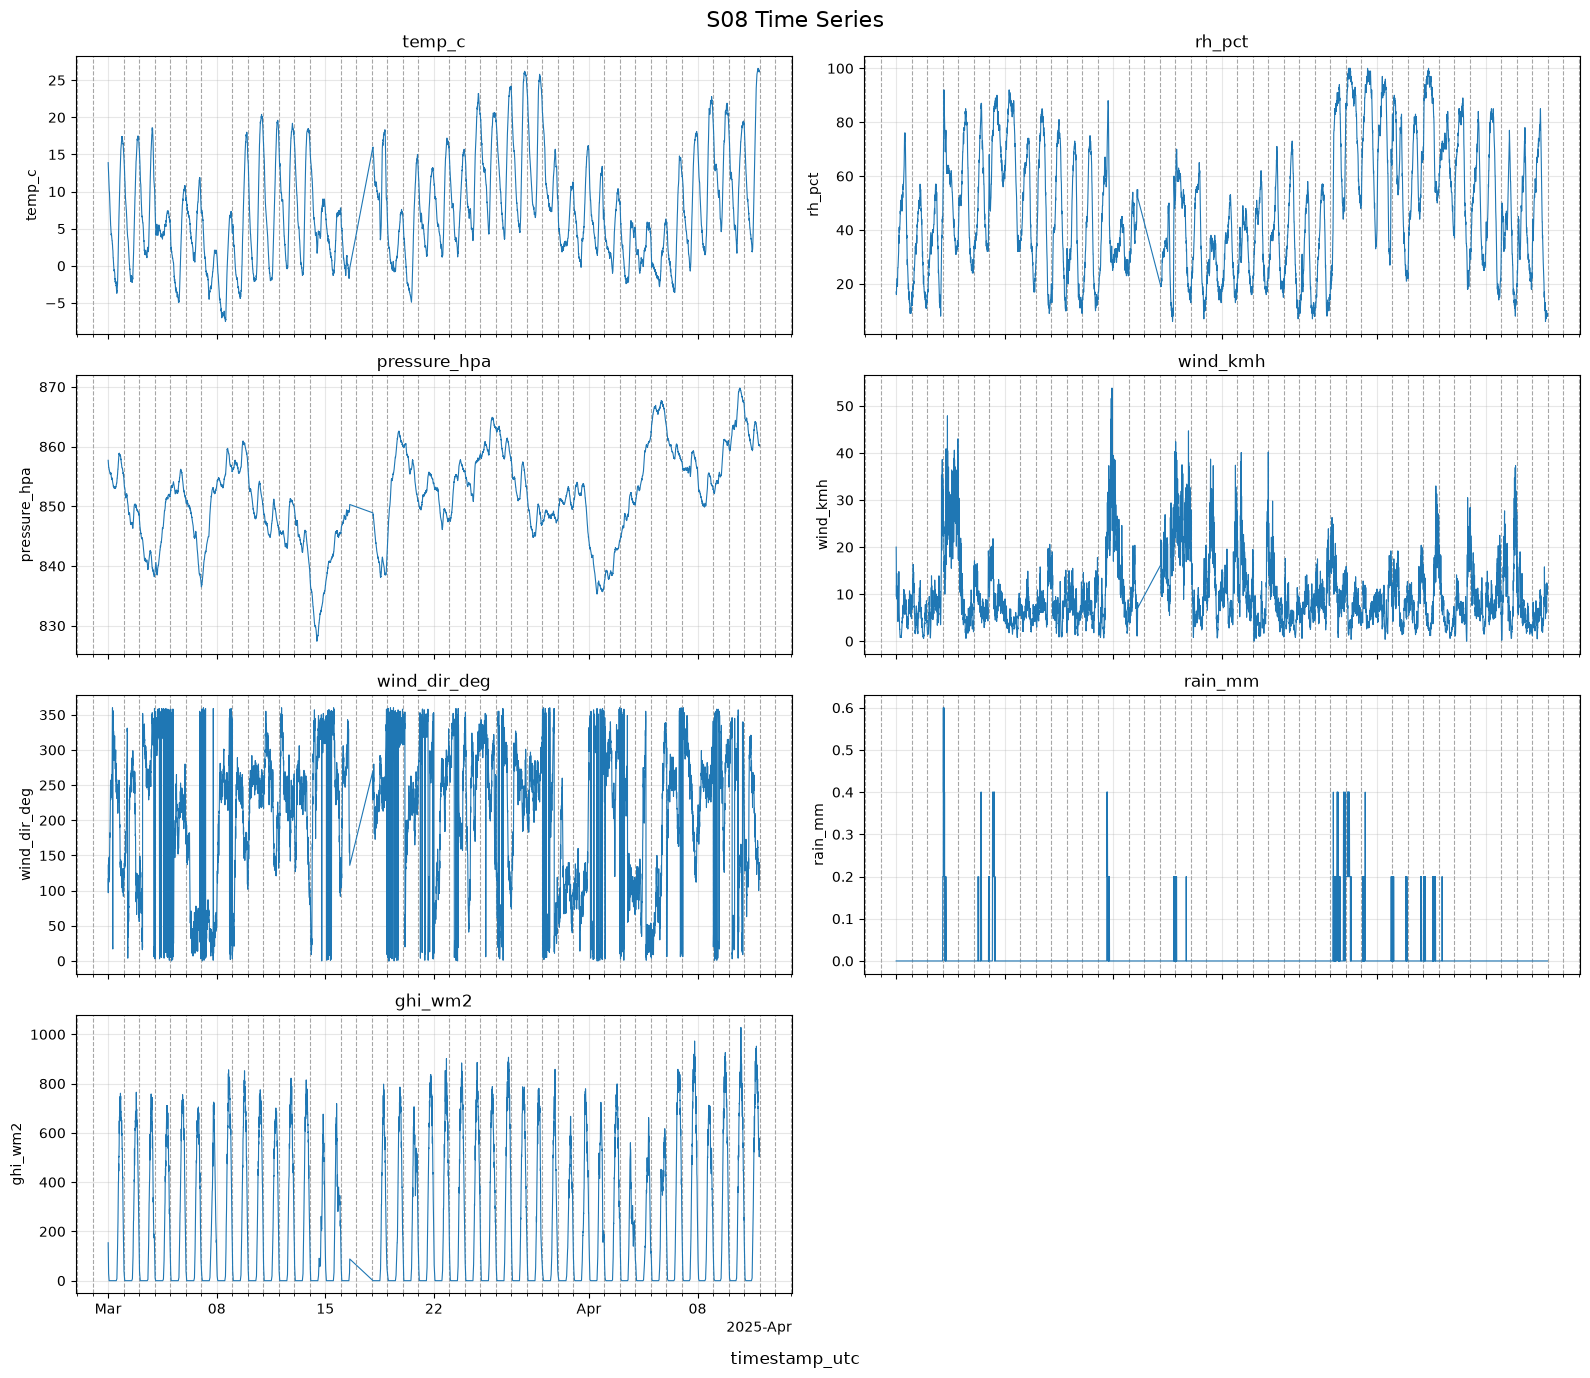

In [21]:
import math
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

time_col = "timestamp_utc"

for station_num in range(1, 9):
    station = f"S{station_num:02d}"

    df = pd.read_csv(
        csv_folder + f"{station}.csv",
        parse_dates=[time_col]
    )
    df = df.dropna(subset=[time_col]).sort_values(time_col)

    value_cols = df.select_dtypes(include="number").columns.tolist()
    ncols = 2
    nrows = math.ceil(len(value_cols) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(16, 3.5 * nrows),
        sharex=True,
        squeeze=False
    )

    for ax, col in zip(axes.flat, value_cols):
        ax.plot(df[time_col], df[col], linewidth=0.8)
        ax.set_title(col)
        ax.set_ylabel(col)
        ax.grid(True, alpha=0.3)

        # Draw a vertical gridline at midnight each day
        ax.xaxis.set_minor_locator(mdates.DayLocator())
        ax.grid(
            which="minor",
            axis="x",
            linestyle="--",
            linewidth=0.8,
            color="gray",
            alpha=0.7
        )

    # Remove unused subplot(s)
    for ax in list(axes.flat)[len(value_cols):]:
        ax.remove()

    locator = mdates.AutoDateLocator()
    formatter = mdates.ConciseDateFormatter(locator)

    for ax in fig.axes:
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(formatter)

    fig.supxlabel(time_col)
    fig.suptitle(f"{station} Time Series", fontsize=16)
    fig.tight_layout()
    plt.show()

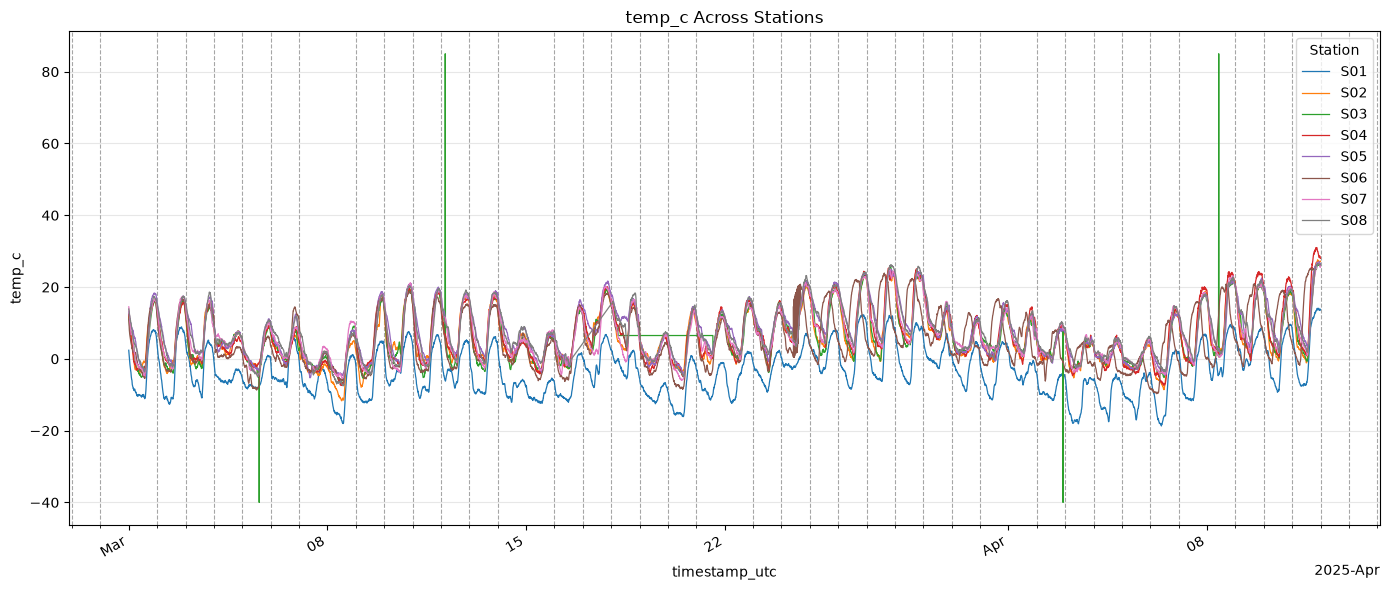

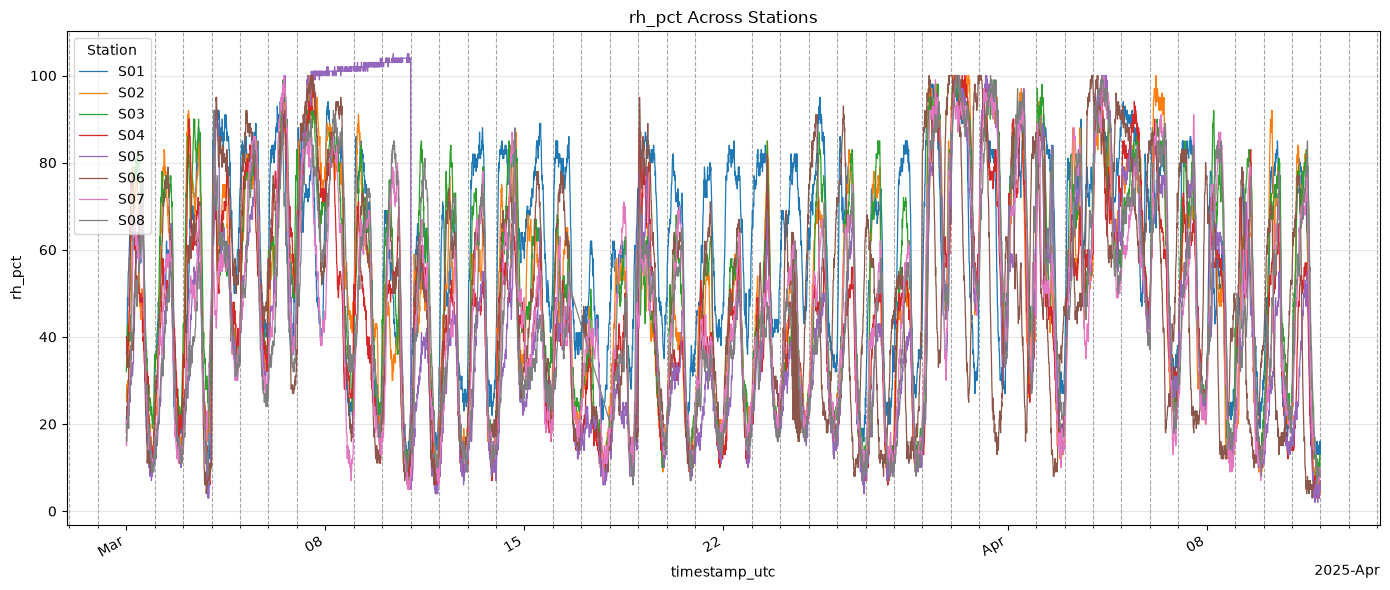

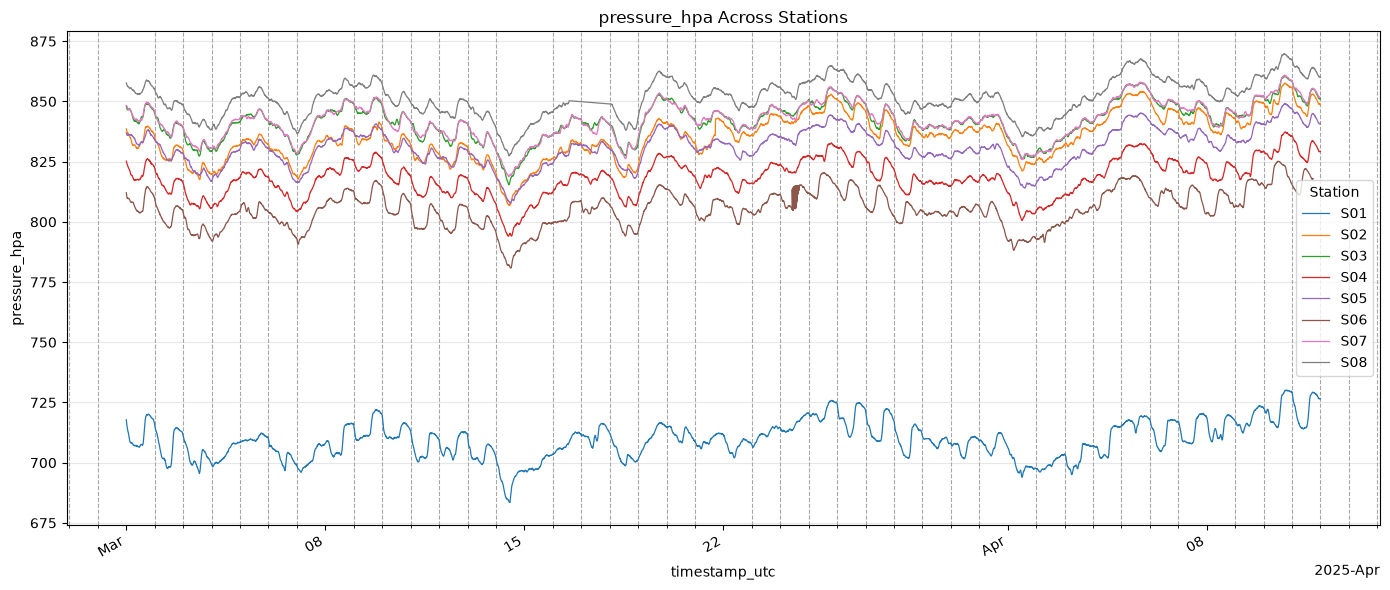

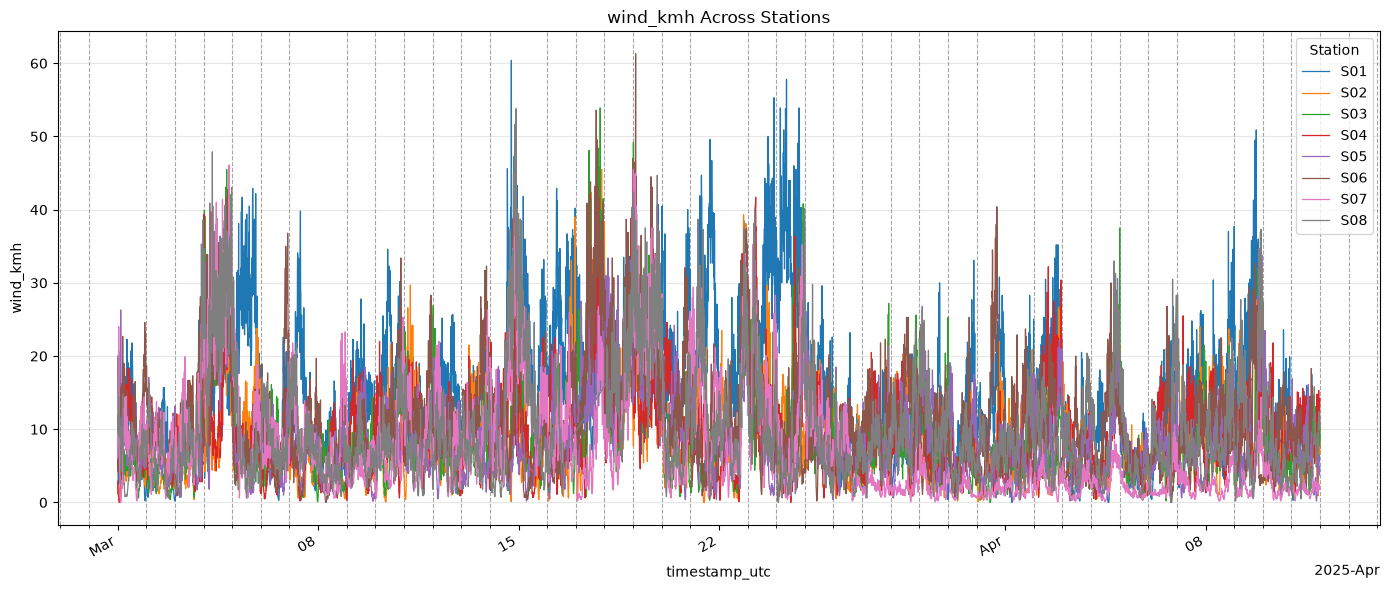

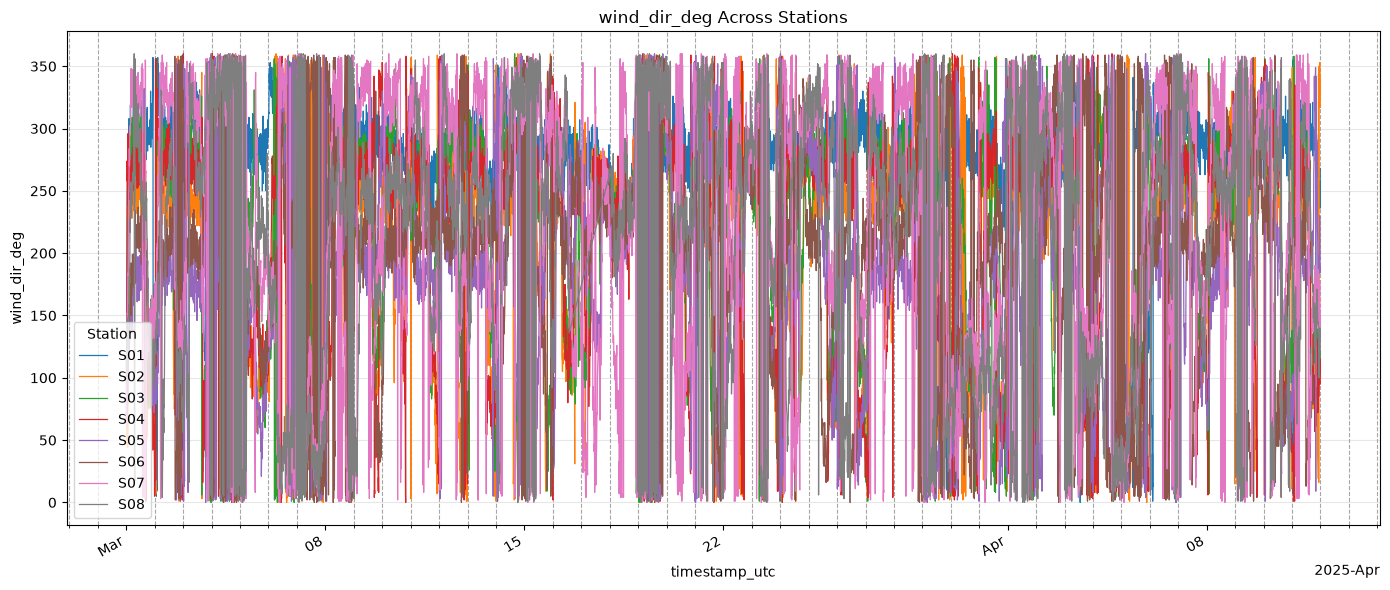

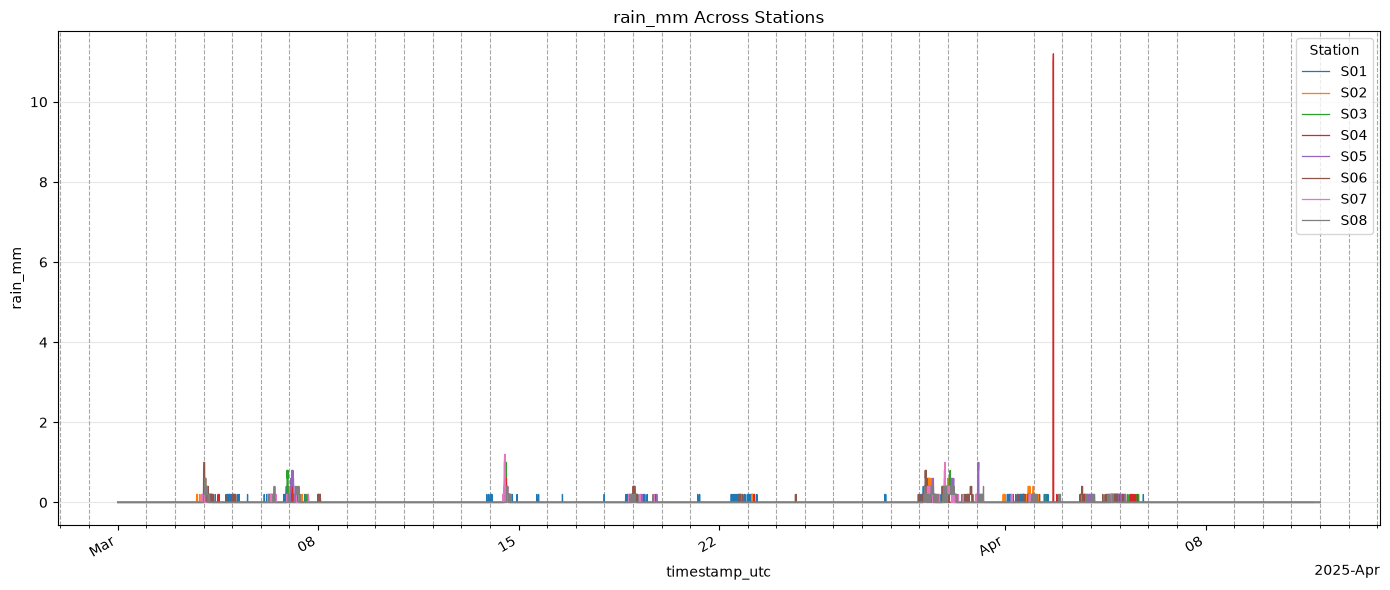

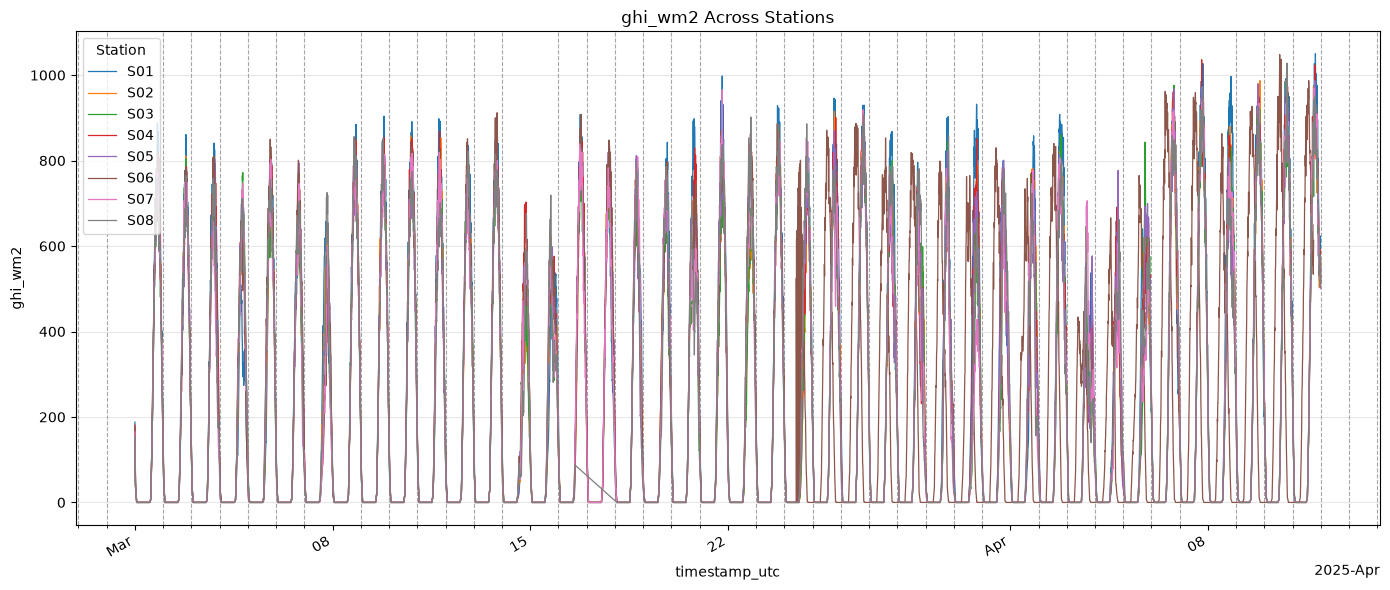

In [22]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

time_col = "timestamp_utc"
stations = [f"S{i:02d}" for i in range(1, 9)]

# Load each station's data and find the numeric features available
station_data = {}
features = []

for station in stations:
    df = pd.read_csv(
        Path(csv_folder) / f"{station}.csv",
        parse_dates=[time_col]
    )
    df = df.dropna(subset=[time_col]).sort_values(time_col)
    station_data[station] = df

    for col in df.select_dtypes(include="number").columns:
        if col not in features:
            features.append(col)

# Create one plot per feature, overlaying all stations
for feature in features:
    fig, ax = plt.subplots(figsize=(14, 6))

    for station, df in station_data.items():
        if feature in df.columns:
            ax.plot(df[time_col], df[feature], linewidth=0.9, label=station)

    ax.set_title(f"{feature} Across Stations")
    ax.set_xlabel(time_col)
    ax.set_ylabel(feature)
    ax.legend(title="Station")
    ax.grid(True, axis="y", alpha=0.3)

    # Vertical gridlines at midnight
    ax.xaxis.set_minor_locator(mdates.DayLocator())
    ax.grid(
        which="minor",
        axis="x",
        linestyle="--",
        linewidth=0.8,
        color="gray",
        alpha=0.7
    )

    locator = mdates.AutoDateLocator()
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))

    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

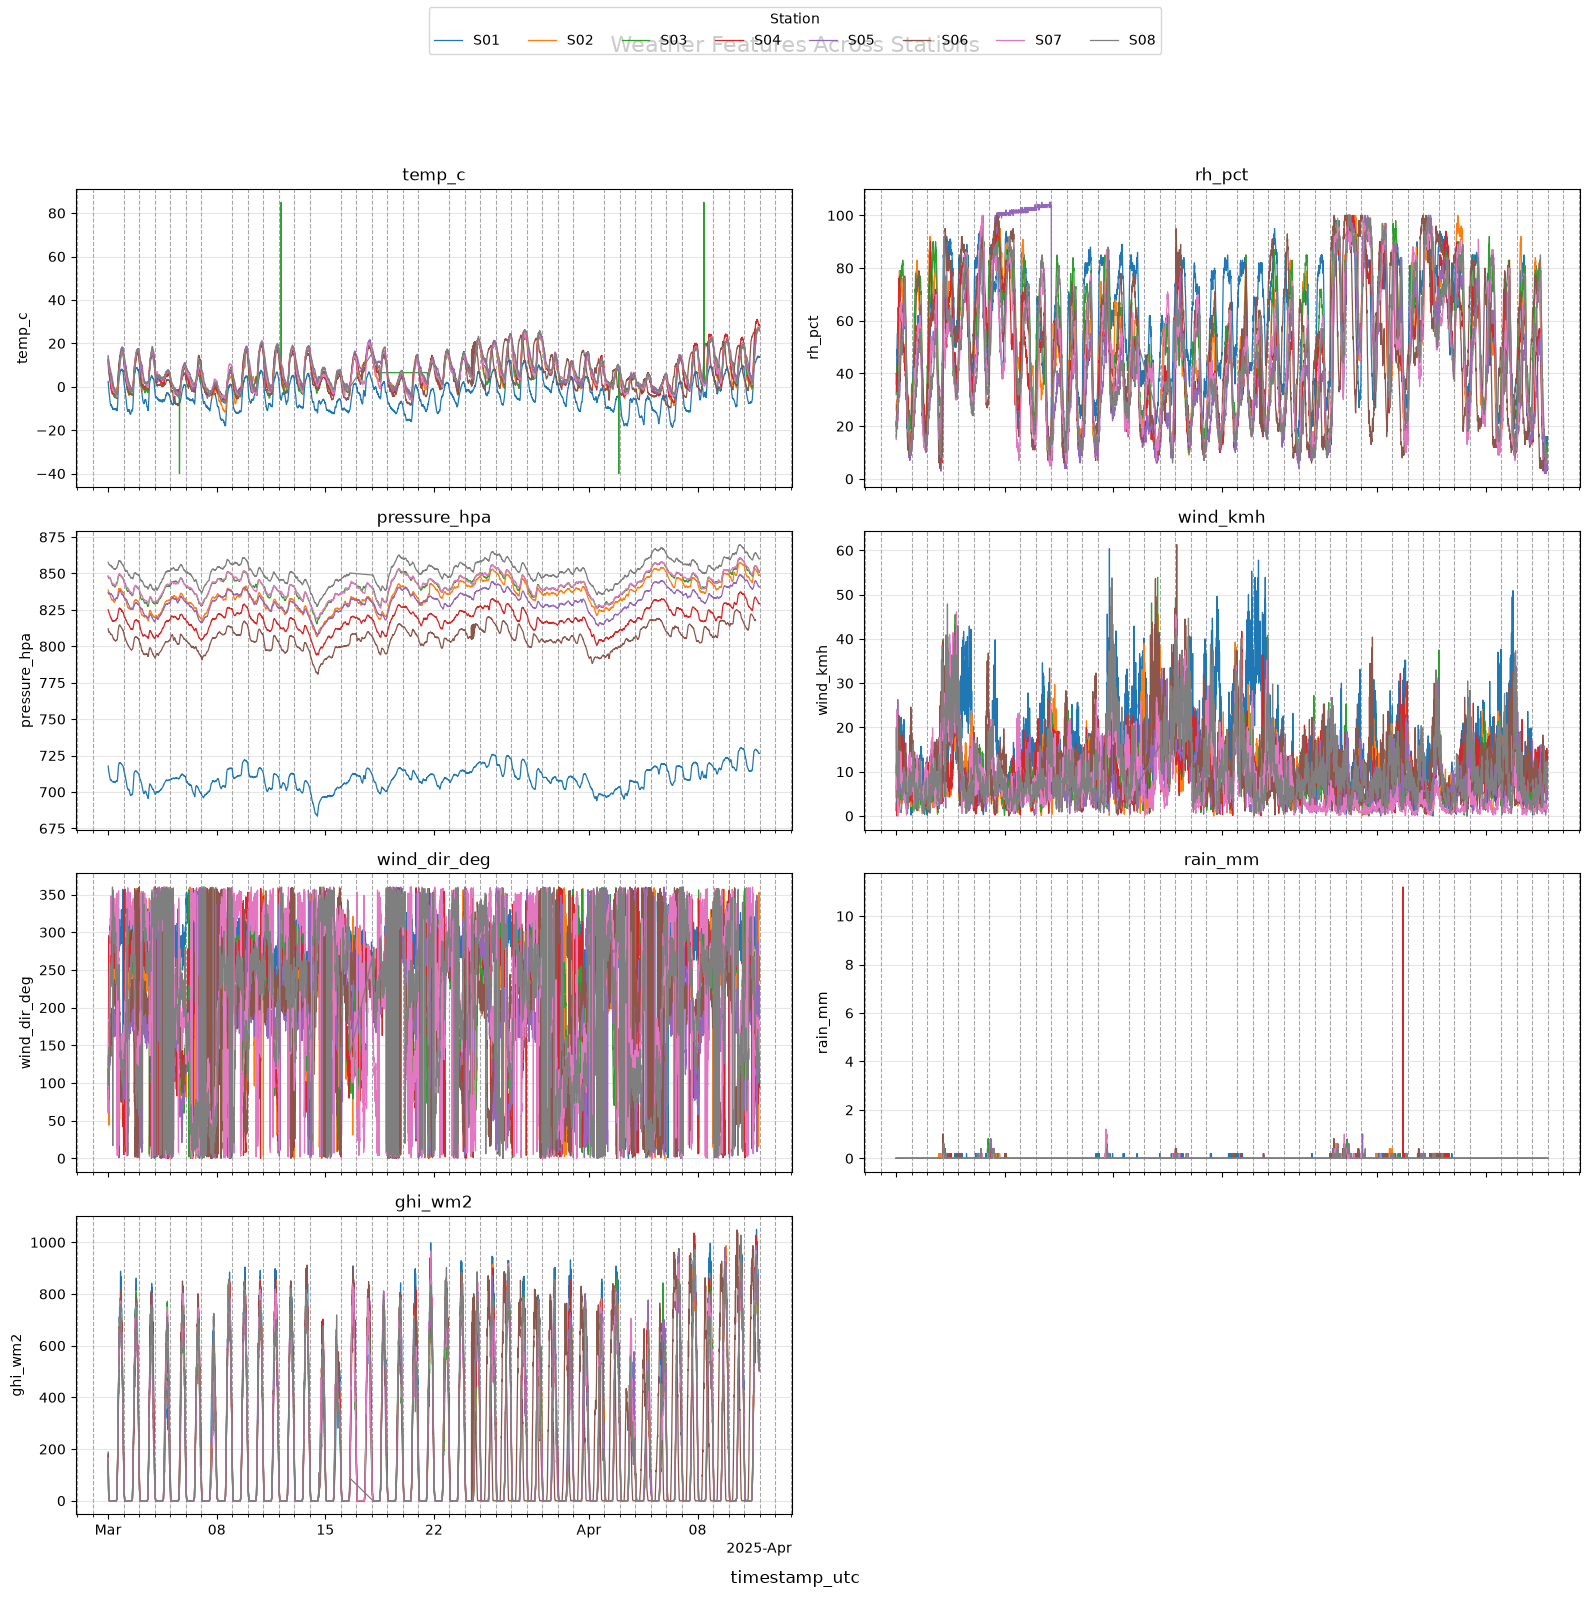

In [23]:
from pathlib import Path
import math
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

time_col = "timestamp_utc"
stations = [f"S{i:02d}" for i in range(1, 9)]

# Load each station's data and collect numeric features
station_data = {}
features = []

for station in stations:
    df = pd.read_csv(
        Path(csv_folder) / f"{station}.csv",
        parse_dates=[time_col]
    )
    df = df.dropna(subset=[time_col]).sort_values(time_col)
    station_data[station] = df

    for col in df.select_dtypes(include="number").columns:
        if col not in features:
            features.append(col)

# Create one subplot per feature, overlaying all stations in each subplot
ncols = 2
nrows = math.ceil(len(features) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(16, 4 * nrows),
    sharex=True,
    squeeze=False
)

for ax, feature in zip(axes.flat, features):
    for station, df in station_data.items():
        if feature in df.columns:
            ax.plot(
                df[time_col],
                df[feature],
                linewidth=0.9,
                label=station
            )

    ax.set_title(feature)
    ax.set_ylabel(feature)
    ax.grid(True, axis="y", alpha=0.3)

    # Vertical gridlines at midnight
    ax.xaxis.set_minor_locator(mdates.DayLocator())
    ax.grid(
        which="minor",
        axis="x",
        linestyle="--",
        linewidth=0.8,
        color="gray",
        alpha=0.7
    )

# Remove unused subplot(s)
for ax in list(axes.flat)[len(features):]:
    ax.remove()

# Format dates and add a shared legend
locator = mdates.AutoDateLocator()
formatter = mdates.ConciseDateFormatter(locator)

for ax in fig.axes:
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(formatter)

handles, labels = fig.axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Station", loc="upper center", ncol=8)

fig.supxlabel(time_col)
fig.suptitle("Weather Features Across Stations", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [26]:
# If needed, install once in a notebook cell:
# pip install folium

import pandas as pd
import folium

stations = pd.read_csv(stations_data)

# Center the map on the average station coordinates
station_map = folium.Map(
    location=[stations["lat"].mean(), stations["lon"].mean()],
    zoom_start=9
)

for _, station in stations.iterrows():
    folium.Marker(
        location=[station["lat"], station["lon"]],
        tooltip=station["station_id"],
        popup=f'{station["name"]} ({station["station_id"]})',
    ).add_to(station_map)

station_map.save("station_map.html")

In [27]:
from pathlib import Path
import pandas as pd

csv_folder = Path(csv_folder)  # Use your existing csv_folder variable

for file_path in sorted(csv_folder.glob("S*.csv")):
    df = pd.read_csv(file_path)

    missing = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": (df.isna().mean() * 100).round(2),
    })

    print(f"\n{file_path.stem} — {len(df)} rows")
    print(missing[missing["missing_count"] > 0])


S01 — 6048 rows
Empty DataFrame
Columns: [missing_count, missing_percent]
Index: []

S02 — 6048 rows
Empty DataFrame
Columns: [missing_count, missing_percent]
Index: []

S03 — 6048 rows
Empty DataFrame
Columns: [missing_count, missing_percent]
Index: []

S04 — 6048 rows
Empty DataFrame
Columns: [missing_count, missing_percent]
Index: []

S05 — 6048 rows
Empty DataFrame
Columns: [missing_count, missing_percent]
Index: []

S06 — 6048 rows
Empty DataFrame
Columns: [missing_count, missing_percent]
Index: []

S07 — 6048 rows
Empty DataFrame
Columns: [missing_count, missing_percent]
Index: []

S08 — 5978 rows
Empty DataFrame
Columns: [missing_count, missing_percent]
Index: []


In [28]:
from pathlib import Path
import pandas as pd

csv_folder = Path(csv_folder)  # Uses the csv_folder variable already in your notebook

for file_path in sorted(csv_folder.glob("S*.csv")):
    df = pd.read_csv(file_path)
    numeric_df = df.select_dtypes(include="number")

    results = []

    for column in numeric_df.columns:
        values = numeric_df[column].dropna()
        mean_value = values.mean()

        if mean_value == 0:
            above_count = float("nan")
            below_count = float("nan")
        else:
            # Compare each value with thresholds 10% above and below the mean.
            margin = abs(mean_value) * 0.10
            above_count = (values > mean_value + margin).sum()
            below_count = (values < mean_value - margin).sum()

        results.append({
            "column": column,
            "mean": mean_value,
            "values_10%_above_mean": above_count,
            "values_10%_below_mean": below_count,
        })

    print(f"\n{file_path.stem}")
    print(pd.DataFrame(results).to_string(index=False))


S01
      column       mean  values_10%_above_mean  values_10%_below_mean
      temp_c  -3.624785                   2647                   3187
      rh_pct  59.500331                   2844                   2364
pressure_hpa 709.428786                      0                      0
    wind_kmh  14.508466                   2197                   3107
wind_dir_deg 271.570933                   1696                    719
     rain_mm   0.013228                    357                   5691
     ghi_wm2 226.439484                   2131                   3780

S02
      column       mean  values_10%_above_mean  values_10%_below_mean
      temp_c   5.825132                   2408                   3344
      rh_pct  50.391204                   2537                   2647
pressure_hpa 835.150595                      0                      0
    wind_kmh   8.869924                   2146                   3246
wind_dir_deg 192.371858                   3558                   2269
     rain_